# 02 - First ML model: customer segmentation
**Goal:** group customers by behaviour so marketing can target each group differently.

Steps: load data → build RFM features → scale → choose number of clusters → K-Means → profile segments → check against hidden personas.

In [1]:
# 1. Setup: make the shopsmart package importable (not needed if you ran `pip install -e .`)
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

from shopsmart.data import load
from shopsmart.config import CONFIG, path

SEED = CONFIG["project"]["random_seed"]

In [2]:
# 2. Load the datasets by name (paths come from configs/config.yaml)
interactions = load("interactions")
products     = load("products")
users        = load("users")
print(interactions.shape, products.shape, users.shape)
interactions.head()

(354340, 10) (1500, 18) (5000, 9)


,Event ID,User ID,Product ID,Session ID,Interaction Type,Timestamp,Rating,Device,Quantity,Price
0,1,3794,1145,32868,view,2024-11-01 00:07:10,<NA>,Tablet,<NA>,NaN
1,2,3794,1145,32868,click,2024-11-01 00:08:05,<NA>,Tablet,<NA>,NaN
2,3,3794,35,32868,view,2024-11-01 00:10:11,<NA>,Tablet,<NA>,NaN
3,4,3794,420,32868,view,2024-11-01 00:11:11,<NA>,Tablet,<NA>,NaN
4,5,1797,157,15474,view,2024-11-01 00:13:56,<NA>,Mobile,<NA>,NaN


## 3. Feature engineering: RFM + behaviour
- **Recency**: days since the customer's last activity
- **Frequency**: number of purchases
- **Monetary**: total spend
- plus conversion rate, average item price, and the share of browsing in each category

In [3]:
end = interactions["Timestamp"].max()
buys = interactions[interactions["Interaction Type"] == "purchase"].copy()
buys["spend"] = buys["Price"] * buys["Quantity"].fillna(1)

g = interactions.groupby("User ID")
feat = pd.DataFrame({
    "recency_days": (end - g["Timestamp"].max()).dt.days,
    "sessions":     g["Session ID"].nunique(),
    "conv_rate":    g["Interaction Type"].apply(lambda s: (s == "purchase").mean()),
})
feat["frequency"] = buys.groupby("User ID").size()
feat["monetary"]  = buys.groupby("User ID")["spend"].sum()
feat["avg_price"] = buys.groupby("User ID")["Price"].mean()

# share of each customer's activity per category
cat_share = pd.crosstab(interactions["User ID"],
                        interactions["Product ID"].map(products.set_index("Product ID")["Category"]),
                        normalize="index").add_prefix("cat_")
feat = feat.join(cat_share).fillna(0)
print(feat.shape)
feat.describe().T.round(2)

(4932, 15)


,count,mean,std,min,25%,50%,75%,max
recency_days,4932.0,136.708029,179.112339,0.0,20.0,57.5,164.25,729.0
sessions,4932.0,8.741079,4.640828,1.0,5.0,9.0,12.0,26.0
conv_rate,4932.0,0.058335,0.030336,0.0,0.040541,0.059492,0.076923,0.208333
frequency,4932.0,4.429643,3.304053,0.0,2.0,4.0,6.0,23.0
monetary,4932.0,201.914254,194.06633,0.0,58.16,148.83,286.7025,1391.38
avg_price,4932.0,40.177278,28.894172,0.0,20.763833,36.04625,54.495758,253.77
cat_Beauty,4932.0,0.107054,0.192167,0.0,0.0,0.0,0.147059,1.0
cat_Bedding & Linens,4932.0,0.106682,0.178308,0.0,0.0,0.0,0.157512,1.0
cat_Books,4932.0,0.106227,0.199714,0.0,0.0,0.0,0.130435,1.0
cat_Electronics,4932.0,0.113321,0.209252,0.0,0.0,0.0,0.140583,1.0


In [4]:
# 4. Scale: K-Means uses distances, so features must be on the same scale
X = StandardScaler().fit_transform(np.log1p(feat))

## 5. How many segments? Elbow and silhouette

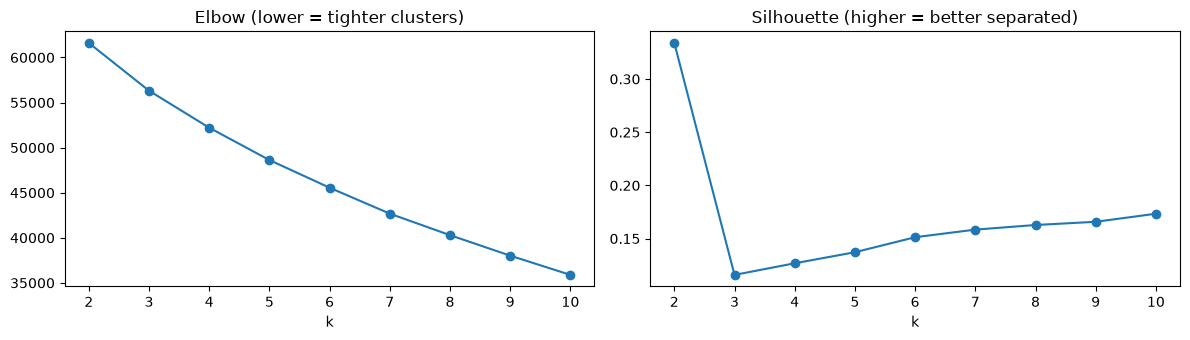

In [5]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=2000, random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ks, inertia, marker="o"); ax[0].set(title="Elbow (lower = tighter clusters)", xlabel="k")
ax[1].plot(ks, sil, marker="o");     ax[1].set(title="Silhouette (higher = better separated)", xlabel="k")
plt.tight_layout(); plt.show()

In [6]:
# 6. Train the final model (change K after reading the charts above)
K = 8
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
feat["segment"] = kmeans.labels_
feat["segment"].value_counts().sort_index()

segment
0    587
1    856
2    482
3    434
4    764
5    467
6    655
7    687
Name: count, dtype: int64

## 7. Profile the segments (this is what marketing reads)

In [7]:
profile = feat.groupby("segment").agg(
    customers=("recency_days", "size"),
    recency_days=("recency_days", "median"),
    purchases=("frequency", "median"),
    spend=("monetary", "median"),
    avg_price=("avg_price", "median"),
)
top_cat = feat.filter(like="cat_").groupby(feat["segment"]).mean().idxmax(axis=1).str.replace("cat_", "")
profile["top_category"] = top_cat
profile.round(1)

,customers,recency_days,purchases,spend,avg_price,top_category
segment,,,,,,
0,587,53.0,5.0,295.6,63.6,Electronics
1,856,53.0,4.0,164.3,43.7,Beauty
2,482,67.5,3.0,85.3,23.6,Books
3,434,134.5,0.0,0.0,0.0,Fashion
4,764,45.5,5.0,216.1,45.1,Fashion
5,467,70.0,4.0,146.8,38.4,Toys
6,655,51.0,5.0,241.9,44.0,Home & Kitchen
7,687,54.0,4.0,100.0,20.0,Food


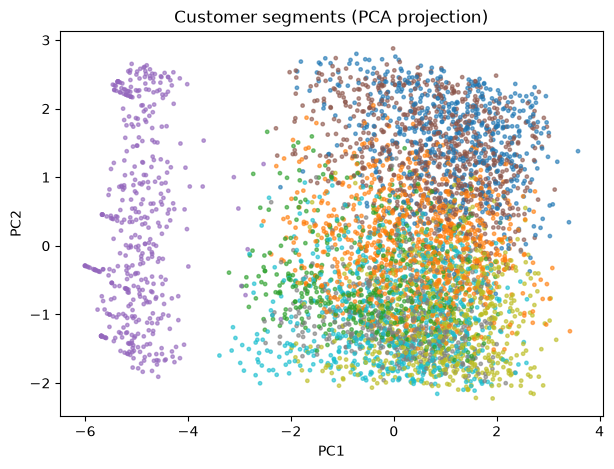

In [8]:
# 8. Visualise in 2D with PCA
xy = PCA(n_components=2, random_state=SEED).fit_transform(X)
plt.figure(figsize=(7, 5))
plt.scatter(xy[:, 0], xy[:, 1], c=feat["segment"], cmap="tab10", s=6, alpha=0.6)
plt.title("Customer segments (PCA projection)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.savefig(path("figures") / "segments_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Evaluate against the hidden personas
The synthetic data has a hidden "true" persona per customer. **Adjusted Rand Index (ARI)**: 0 = random, 1 = perfect match.
This is only possible because the data is synthetic. With real data you'd judge segments by business usefulness.

In [9]:
truth = load("personas_truth").set_index("User ID").loc[feat.index, "Persona"]
print("ARI:", round(adjusted_rand_score(truth, feat["segment"]), 3))
pd.crosstab(feat["segment"], truth)

ARI: 0.211


Persona,Bargain Hunter,Bookworm Homebody,Busy Parent,Fitness Enthusiast,Premium Loyalist,Seasonal Gifter,Self-Care Lover,Young Techie
segment,,,,,,,,
0,12,14,10,65,119,21,10,336
1,111,60,32,14,158,42,427,12
2,9,260,63,6,7,53,13,71
3,64,48,60,56,26,54,54,72
4,71,18,8,416,36,13,52,150
5,11,12,313,10,6,93,9,13
6,273,68,152,14,121,8,10,9
7,294,98,107,81,3,59,40,5


In [ ]:
# 10. Save the segments for later steps (recommender, dashboard)
out = path("processed_data") / "customer_segments.csv"
feat[["segment"]].to_csv(out)
print("Saved", out)

NameError: name 'path' is not defined

: 

## Next ideas
- Try **GMM** or **DBSCAN** instead of K-Means and compare ARI
- Name each segment (e.g. "Bargain Hunters") from the profile table
- Later: replace the hand-made features with **autoencoder embeddings** (deep learning) and see if ARI improves